## 1. Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier


In [ ]:
df = pd.read_csv('/content/cumulative.csv')
df

In [ ]:
df.shape

In [ ]:
df.head()

In [ ]:
df.tail()

In [ ]:
df.sample(min(5, len(df)), random_state=42)

In [ ]:
df.info()

In [ ]:
df.describe()

In [ ]:
df.describe(include="object")

In [ ]:
print("Number of duplicated rows:", df.duplicated().sum())
print("\nMissing values per column:")
display(df.isnull().sum().to_frame("Missing Values").query("`Missing Values` > 0"))

In [ ]:
missing_summary = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": df.isnull().mean() * 100
})
missing_summary = missing_summary[missing_summary["Missing Values"] > 0]
display(missing_summary.sort_values("Missing Percentage", ascending=False))

## 4. Check Data Types and Categories

In [ ]:
numerical_columns = df.select_dtypes(include=np.number).columns.tolist()
categorical_columns = df.select_dtypes(exclude=np.number).columns.tolist()

print("Numerical columns:", numerical_columns)
print("\nCategorical columns:", categorical_columns)

Value Count

In [ ]:
for column in categorical_columns:
    print(f"\\n{column}")
    print(df[column].value_counts(dropna=False).head(20))

::## 5. Exploratory Data Analysis

Target Distribution

In [ ]:
TARGET = "koi_disposition"

if TARGET not in df.columns:
    raise KeyError(f"Target column '{TARGET}' was not found in the dataset.")

display(df[TARGET].value_counts(dropna=False).to_frame("Count"))

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x=TARGET, order=df[TARGET].value_counts().index)
plt.title("Target Class Distribution")
plt.xlabel("Disposition")
plt.ylabel("Count")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

### Numerical Feature Distributions

In [ ]:
candidate_numerical_features = [
    "koi_period", "koi_duration", "koi_depth", "koi_prad", "koi_teq"
]
numerical_features = [
    column for column in candidate_numerical_features
    if column in df.columns and pd.api.types.is_numeric_dtype(df[column])
]

for column in numerical_features:
    plt.figure(figsize=(7, 4))
    sns.histplot(data=df, x=column, kde=True)
    plt.title(f"Distribution of {column}")
    plt.tight_layout()
    plt.show()

###  Categorical Feature Analysis

In [ ]:
candidate_categorical_features = ["koi_disposition", "koi_pdisposition"]
categorical_features = [
    column for column in candidate_categorical_features if column in df.columns
]

for column in categorical_features:
    plt.figure(figsize=(7, 4))
    sns.countplot(data=df, x=column, order=df[column].value_counts().index)
    plt.title(f"{column} Distribution")
    plt.xlabel(column)
    plt.ylabel("Count")
    plt.xticks(rotation=25)
    plt.tight_layout()
    plt.show()

###Correlation Heatmap

In [ ]:
correlation = df[numerical_features].corr()

plt.figure(figsize=(10,7))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    center=0
)

plt.title('Correlation Heatmap')
plt.show()

###Numerical Features vs Target

In [ ]:
for col in numerical_features:

    plt.figure(figsize=(8,5))

    sns.boxplot(
        data=df,
        x='koi_disposition',
        y=col
    )

    plt.title(f'{col} vs Disposition')
    plt.xticks(rotation=15)
    plt.show()

## 6. Data Cleaning

In [ ]:
drop_columns = [
    "rowid",
    "kepid",
    "kepoi_name",
    "kepler_name",
    "koi_pdisposition",     #Data leakage
    "koi_score",         # Validation score; excluded to avoid leakage.
    "koi_fpflag_nt",
    "koi_fpflag_ss",
    "koi_fpflag_co",
    "koi_fpflag_ec",
    "koi_tce_delivname"
]

df_clean = df.drop(columns=drop_columns, errors="ignore").copy()

df_clean = df_clean.dropna(subset=[TARGET])
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

print("Original shape:", df.shape)
print("Shape after cleaning:", df_clean.shape)
print("Target classes:")
print(df_clean[TARGET].value_counts())

###  Review Missing Values

In [ ]:
missing_after_cleaning = pd.DataFrame({
    "Missing Values": df_clean.isnull().sum(),
    "Missing Percentage": df_clean.isnull().mean() * 100
})
missing_after_cleaning = missing_after_cleaning[
    missing_after_cleaning["Missing Values"] > 0
]
display(missing_after_cleaning.sort_values("Missing Percentage", ascending=False))

### Remove Columns with No Useful Values

In [ ]:
# Drop columns that are completely empty.
all_missing_columns = df_clean.columns[df_clean.isnull().all()].tolist()
print("Completely empty columns:", all_missing_columns)

df_clean = df_clean.drop(columns=all_missing_columns)
print("Shape after dropping completely empty columns:", df_clean.shape)

## 7. Separate Features and Target

In [ ]:
X = df_clean.drop(columns=[TARGET])
y = df_clean[TARGET]

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget distribution:")
display(y.value_counts())

 8. Check Outliers


In [ ]:
outlier_cols = [
    'koi_depth',
    'koi_period',
    'koi_model_snr',
    'koi_prad',
    'koi_insol',
    'koi_duration'
]

Q1 = X[outlier_cols].quantile(0.25)
Q3 = X[outlier_cols].quantile(0.75)
IQR = Q3 - Q1

outliers = ((X[outlier_cols] < Q1 - 1.5 * IQR) |
            (X[outlier_cols] > Q3 + 1.5 * IQR)).sum()

print(outliers)

In [ ]:
for col in outlier_cols:
    plt.figure(figsize=(7, 4))
    sns.boxplot(x=X[col])
    plt.title(col)
    plt.show()

9. Check Missing Values



In [ ]:
print(X.isnull().sum()[X.isnull().sum() > 0])

 10. Train-Test Split


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

In [ ]:
y_train.value_counts()

 11. Handle Missing Values


In [ ]:
medians = X_train.median()

X_train = X_train.fillna(medians)
X_test = X_test.fillna(medians)

print("Missing values:", X_train.isnull().sum().sum(),
      X_test.isnull().sum().sum())

12. Handle Outliers



In [ ]:
for col in outlier_cols:

    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    X_train[col] = X_train[col].clip(lower, upper)
    X_test[col] = X_test[col].clip(lower, upper)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

 13. Target Encoding


In [ ]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()
y_train = encoder.fit_transform(y_train)
y_test = encoder.transform(y_test)

print(encoder.classes_)

In [ ]:
import pandas as pd
from imblearn.over_sampling import SMOTE

smote = SMOTE(
    sampling_strategy="not majority",
    random_state=42,
    k_neighbors=5
)

X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print("Before SMOTE:")
print(pd.Series(y_train).value_counts())

print("\nAfter SMOTE:")
print(pd.Series(y_train_smote).value_counts())

## 14. Feature Scaling



In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

##Model Random Forest

## 15. Model Training


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, f1_score

model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred))
print("Train accuracy:", round(model.score(X_train, y_train), 3))
print("Test accuracy :", round(model.score(X_test, y_test), 3))
print("Test F1       :", round(f1_score(y_test, y_pred, average='weighted'), 3))

## 16. Model Evaluation

In [ ]:
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, f1_score

model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    eval_metric="mlogloss",
    random_state=42
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred))
print("Train accuracy:", round(model.score(X_train, y_train), 3))
print("Test accuracy :", round(model.score(X_test, y_test), 3))
print("Test F1       :", round(f1_score(y_test, y_pred, average='weighted'), 3))

In [ ]:
################################ with cross vaild
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import make_scorer, f1_score
from xgboost import XGBClassifier
import numpy as np

y_encoded = encoder.transform(y)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "baseline": XGBClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=6,
        subsample=0.8, colsample_bytree=0.8,
        objective="multi:softprob", eval_metric="mlogloss",
        random_state=42
    ),
    "regularized_depth_3": XGBClassifier(
        n_estimators=300, learning_rate=0.03, max_depth=3,
        min_child_weight=5, gamma=0.5,
        reg_alpha=1, reg_lambda=5,
        subsample=0.7, colsample_bytree=0.7,
        objective="multi:softprob", eval_metric="mlogloss",
        random_state=42
    ),
    "regularized_depth_4": XGBClassifier(
        n_estimators=300, learning_rate=0.03, max_depth=4,
        min_child_weight=5, gamma=0.5,
        reg_alpha=1, reg_lambda=5,
        subsample=0.7, colsample_bytree=0.7,
        objective="multi:softprob", eval_metric="mlogloss",
        random_state=42
    )
}

scoring = {
    "accuracy": "accuracy",
    "macro_f1": make_scorer(f1_score, average="macro")
}

for name, estimator in models.items():
    pipeline = make_pipeline(SimpleImputer(strategy="median"), estimator)
    scores = cross_validate(
        pipeline, X, y_encoded, cv=cv, scoring=scoring,
        return_train_score=True, n_jobs=-1
    )

    print(f"\n{name}")
    for metric in ["accuracy", "macro_f1"]:
        train = scores[f"train_{metric}"]
        valid = scores[f"test_{metric}"]
        print(
            f"{metric}: train={train.mean():.3f}, "
            f"validation={valid.mean():.3f}, "
            f"gap={train.mean() - valid.mean():.3f}"
        )

In [37]:
from sklearn.ensemble import VotingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, f1_score
model = VotingClassifier(
    estimators=[
        ("logistic", LogisticRegression(max_iter=2000, class_weight="balanced")),
        ("svm", SVC(kernel="rbf", probability=True, class_weight="balanced")),
        ("tree", DecisionTreeClassifier(max_depth=15, class_weight="balanced")),
        ("forest", RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ],
    voting="hard"
)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Train accuracy:", round(model.score(X_train, y_train), 3))
print("Test accuracy :", round(model.score(X_test, y_test), 3))
print("Test F1       :", round(f1_score(y_test, y_pred, average='weighted'), 3))
print(classification_report(y_test, y_pred))

Train accuracy: 0.855
Test accuracy : 0.75
Test F1       : 0.756
              precision    recall  f1-score   support

           0       0.51      0.62      0.56       449
           1       0.79      0.84      0.82       459
           2       0.87      0.76      0.81      1005

    accuracy                           0.75      1913
   macro avg       0.73      0.74      0.73      1913
weighted avg       0.77      0.75      0.76      1913



Train accuracy: 0.73
Test accuracy : 0.755
Test F1       : 0.742
Train F1      :
                precision    recall  f1-score   support

     CANDIDATE       0.58      0.40      0.47       449
     CONFIRMED       0.77      0.85      0.81       459
FALSE POSITIVE       0.80      0.87      0.83      1005

      accuracy                           0.76      1913
     macro avg       0.72      0.71      0.70      1913
  weighted avg       0.74      0.76      0.74      1913



<Axes: >

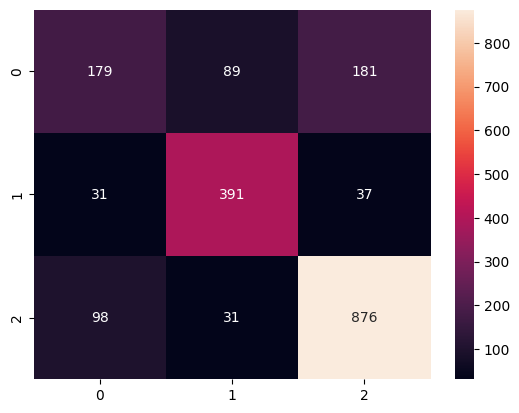

In [50]:
model = LogisticRegression( )
model.fit(X_train, y_train)
print("Train accuracy:", round(model.score(X_train, y_train), 3))
print("Test accuracy :", round(model.score(X_test, y_test), 3))
print("Test F1       :", round(f1_score(y_test, model.predict(X_test), average='weighted'), 3))
print("Train F1      :"), round(f1_score(y_train, model.predict(X_train), average='weighted'), 3)
print(classification_report(y_test, y_pred, target_names=encoder.classes_))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d')



Accuracy: 0.7496079456351281
                precision    recall  f1-score   support

     CANDIDATE       0.51      0.62      0.56       449
     CONFIRMED       0.79      0.84      0.82       459
FALSE POSITIVE       0.87      0.76      0.81      1005

      accuracy                           0.75      1913
     macro avg       0.73      0.74      0.73      1913
  weighted avg       0.77      0.75      0.76      1913



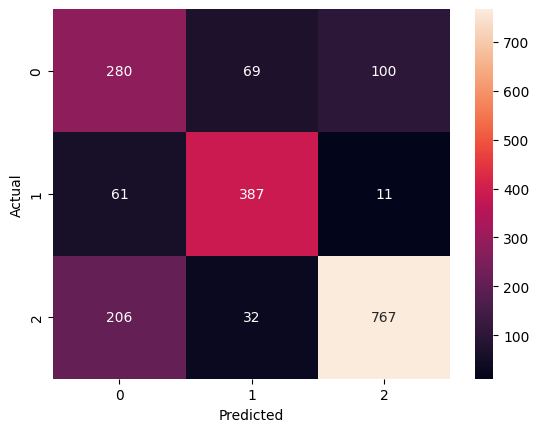

In [42]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=encoder.classes_))

sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [40]:
#gradio
!pip install -q gradio

import os, tempfile
import numpy as np
import pandas as pd
import gradio as gr
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score
from xgboost import XGBClassifier

# ---------- Reuse notebook objects ----------
FEATURES = X.columns.tolist()
CLASSES = encoder.classes_.tolist()

# Clipping bounds (same as step 12; recomputed because they weren't stored)
_Xtr_raw, _, _, _ = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
_Xtr_raw = _Xtr_raw.fillna(medians)
BOUNDS = {}
for c in outlier_cols:
    q1, q3 = _Xtr_raw[c].quantile(0.25), _Xtr_raw[c].quantile(0.75)
    iqr = q3 - q1
    BOUNDS[c] = (q1 - 1.5 * iqr, q3 + 1.5 * iqr)

# Final model (XGBoost, trained on the already-scaled X_train)
final_model = XGBClassifier(
    n_estimators=300, learning_rate=0.05, max_depth=6,
    subsample=0.8, colsample_bytree=0.8,
    objective="multi:softprob", eval_metric="mlogloss", random_state=42,
).fit(X_train, y_train)

_pred = final_model.predict(X_test)
ACC = accuracy_score(y_test, _pred)
F1 = f1_score(y_test, _pred, average="weighted")

# ---------- Prediction ----------
def preprocess(df):
    df = df.reindex(columns=FEATURES).apply(pd.to_numeric, errors="coerce").fillna(medians)
    for c, (lo, hi) in BOUNDS.items():
        df[c] = df[c].clip(lo, hi)
    return scaler.transform(df)

def predict_single(*vals):
    row = {c: (np.nan if v is None else v) for c, v in zip(FEATURES, vals)}
    proba = final_model.predict_proba(preprocess(pd.DataFrame([row])))[0]
    return {cls: float(p) for cls, p in zip(CLASSES, proba)}

def predict_batch(file):
    if file is None:
        raise gr.Error("Please upload a CSV file first.")
    df = pd.read_csv(file if isinstance(file, str) else file.name)
    if not set(FEATURES) & set(df.columns):
        raise gr.Error("The file contains none of the required feature columns.")

    proba = final_model.predict_proba(preprocess(df))
    out = df.copy()
    out["prediction"] = [CLASSES[i] for i in proba.argmax(axis=1)]
    out["confidence"] = proba.max(axis=1).round(4)
    for i, cls in enumerate(CLASSES):
        out[f"prob_{cls}"] = proba[:, i].round(4)

    path = os.path.join(tempfile.gettempdir(), "kepler_predictions.csv")
    out.to_csv(path, index=False)
    summary = out["prediction"].value_counts().rename_axis("class").reset_index(name="count")
    return summary, out.head(200), path

# ---------- UI Setup ----------
main_features_dict = {
    "koi_period": "Orbital period (days)",
    "koi_time0bk": "Transit epoch (BKJD)",
    "koi_impact": "Impact parameter",
    "koi_duration": "Transit duration (hrs)",
    "koi_depth": "Transit depth (ppm)",
    "koi_prad": "Planet radius (Earth radii)",
    "koi_teq": "Equilibrium temperature (K)",
    "koi_insol": "Insolation flux (Earth flux)",
    "koi_model_snr": "Transit signal-to-noise",
    "koi_tce_plnt_num": "TCE planet number",
    "koi_steff": "Star temperature (K)",
    "koi_slogg": "Star surface gravity (log10 cm/s²)",
    "koi_srad": "Star radius (Solar radii)",
    "ra": "Right ascension (deg)",
    "dec": "Declination (deg)",
    "koi_kepmag": "Kepler magnitude",
}

main_cols = [c for c in main_features_dict if c in FEATURES]
adv_cols = [c for c in FEATURES if c not in main_cols]
UI_COLS = main_cols + adv_cols

def default(col):
    return float(round(medians[col], 6))

with gr.Blocks(title="Kepler Exoplanet Classifier") as demo:
    gr.Markdown(
        "# 🪐 Kepler Exoplanet Classifier\n"
        "Classifies each KOI as **CONFIRMED / CANDIDATE / FALSE POSITIVE**.\n\n"
        f"**Test accuracy:** {ACC:.3f} · "
        f"**Weighted F1:** {F1:.3f}"
    )

    with gr.Tab("Single Prediction"):
        inputs = []
        with gr.Row():
            half = len(main_cols) // 2
            for chunk in (main_cols[:half], main_cols[half:]):
                with gr.Column():
                    for c in chunk:
                        inputs.append(gr.Number(label=f"{c} — {main_features_dict[c]}", value=default(c)))
        with gr.Accordion("Error columns (optional — defaults to the median)", open=False):
            with gr.Row():
                for i in range(0, len(adv_cols), 10):
                    with gr.Column():
                        for c in adv_cols[i:i + 10]:
                            inputs.append(gr.Number(label=c, value=default(c)))
        btn = gr.Button("Predict", variant="primary")
        label = gr.Label(num_top_classes=3, label="Prediction")
        btn.click(predict_single, inputs=inputs, outputs=label)

    with gr.Tab("Batch Prediction (CSV)"):
        gr.Markdown("Upload a file with the same columns as `cumulative.csv` (missing columns are filled with the median).")
        file_in = gr.File(label="CSV file", file_types=[".csv"])
        run = gr.Button("Predict batch", variant="primary")
        summary = gr.Dataframe(label="Summary")
        preview = gr.Dataframe(label="Preview (first 200 rows)")
        download = gr.File(label="Download predictions")
        run.click(predict_batch, inputs=file_in, outputs=[summary, preview, download])

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://8561a1752efa382890.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
